In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
# on charge les données 
encounters = pd.read_csv("cleaned/clinical_encounters_cleaned.csv")
notes = pd.read_csv("cleaned/clinical_notes_cleaned.csv")
observation = pd.read_csv("cleaned/clinical_observation_cleaned.csv")
procedure = pd.read_csv("cleaned/clinical_procedures_cleaned.csv")
patients = pd.read_csv("cleaned/patient_administration_cleaned.csv")

## 1. clinical_encounters 

### a) choix des variables et encodage 
Toutes les variables dans ce fichiers sont categorielles. On exclut deja les identifiants purs (encounter_number, patient_number, attending_license_number, etc), et les dates (pour l'instant). Ces variables là n'ont pas de sens sémantique pour regrouper des profils de consultations. On ne garde que les variables médicales et administratives descriptives.

In [3]:
# On exclut les identifiants, les licences, et les dates
cols_a_ignorer = ['encounter_number', 'patient_number', 'attending_license_number', 
                  'facility_license_number', 'encounter_end', 'encounter_start','follow_up_date']
cols_clustering = [c for c in encounters.columns if c not in cols_a_ignorer]

df_features = encounters[cols_clustering].copy()

In [4]:
# Encodage One-Hot
df_encoded = pd.get_dummies(df_features, drop_first=False)

# Standardisation 
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

print(f"Dimensions avant One-Hot Encoding : {df_features.shape}")
print(f"Dimensions après One-Hot Encoding : {df_encoded.shape}")

Dimensions avant One-Hot Encoding : (1067, 5)
Dimensions après One-Hot Encoding : (1067, 29)


Maintenant qu'on a beacoups de matiere avec l'encodage on peut utiliser PCA et T-sne pour visualiser les données et les potentiels clusters

### b) PCA, t-SNE, et choix de la méthode de clustering

In [5]:
# PCA 
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_encoded.values)
encounters['PCA1'] = pca_result[:, 0]
encounters['PCA2'] = pca_result[:, 1]

variance_expliquee = pca.explained_variance_ratio_.sum() * 100
print(f"Variance expliquée par les 2 composantes PCA : {variance_expliquee:.2f}%")

Variance expliquée par les 2 composantes PCA : 19.44%


La variance expliquée par les 2 premières composantes reste faible (19%), la PCA seule ne permet donc pas de bien voir les groupes. Le t-SNE (non linéaire) est plus adapté pour visualiser ce type de données.

In [6]:
# t-SNE 
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(df_encoded.values)
encounters['tSNE1'] = tsne_result[:, 0]
encounters['tSNE2'] = tsne_result[:, 1]

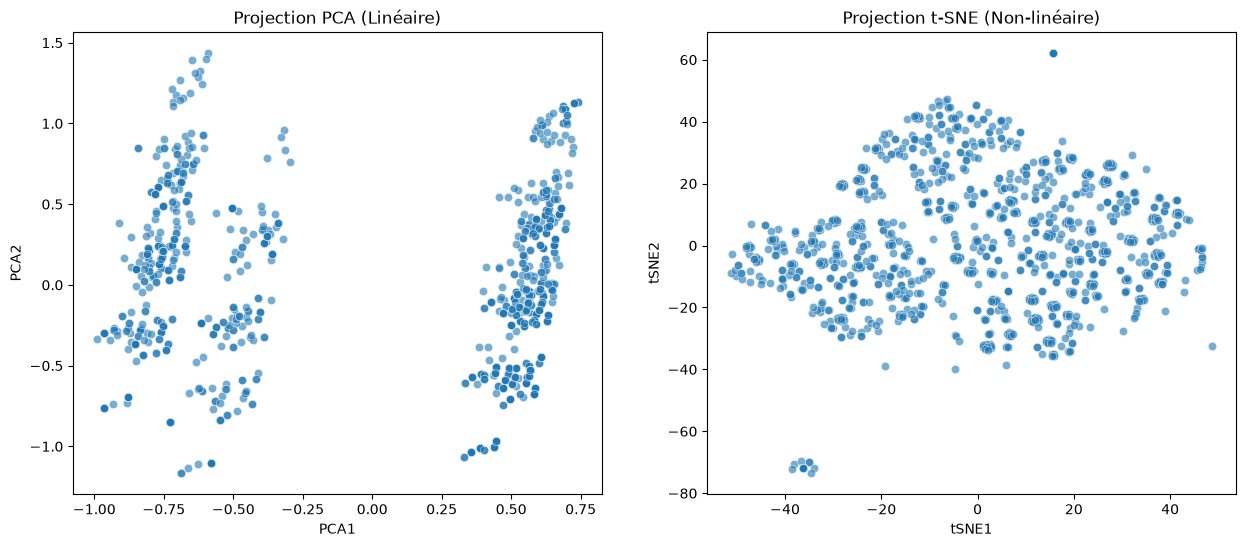

In [7]:
# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='PCA1', y='PCA2', data=encounters, ax=axes[0], alpha=0.6)
axes[0].set_title('Projection PCA (Linéaire)')

sns.scatterplot(x='tSNE1', y='tSNE2', data=encounters, ax=axes[1], alpha=0.6)
axes[1].set_title('Projection t-SNE (Non-linéaire)')
plt.show()

Comme toutes les variables sont nominales, beaucoup de rencontres ont exactement le même profil : les points se superposent et forment des blocs (c'est normal). Ces projections servent donc à visualiser, pas à décider du nombre de clusters.

D'après le cours, les variables nominales encodées en one-hot se comparent avec la distance de Hamming : on part donc sur le Clustering Agglomératif couplé à la distance de Hamming, et on le compare à un K-Means pour vérifier que les groupes ne dépendent pas de l'algorithme. On ne standardise pas les colonnes one-hot (le cours déconseille de normaliser les variables binaires/nominales), `df_scaled` n'est donc plus utilisé.

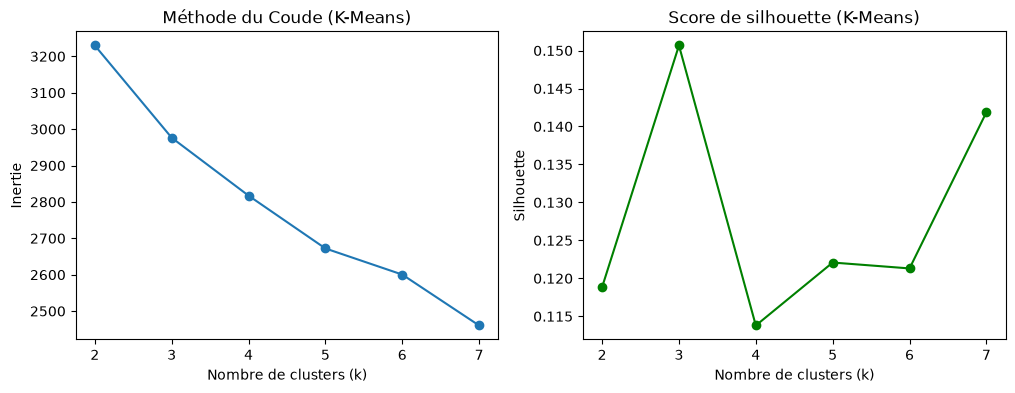

In [8]:
# --- Test K-MEANS (Coude + Silhouette) sur les variables one-hot brutes ---
inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_km = kmeans.fit_predict(df_encoded.values)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(df_encoded.values, labels_km))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Méthode du Coude (K-Means)')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[1].plot(K_range, silhouettes, marker='o', color='green')
axes[1].set_title('Score de silhouette (K-Means)')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Silhouette')
plt.show()

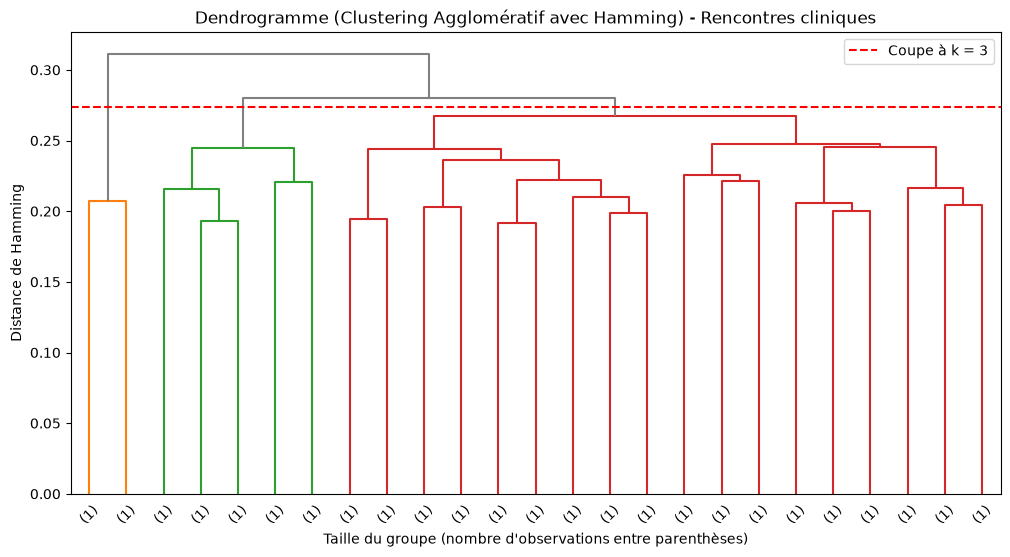

In [9]:
# Choix de K avec la méthode du dendogramme
# On utilise 'linkage' avec la métrique de Hamming sur toutes les lignes (comme l'AgglomerativeClustering plus bas),
# pour que le dendrogramme corresponde exactement aux clusters obtenus
Z = linkage(df_encoded.values.astype(float), method='average', metric='hamming')

# Hauteur de coupe qui donne k clusters (entre les deux dernières fusions conservées)
k_optimal = 3
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 6))
# (n) = nombre d'observations regroupées dans la branche ; (1) = observation seule
dendrogram(Z, truncate_mode='lastp', p=25, show_leaf_counts=True, leaf_label_func=lambda i: '(1)',
           color_threshold=seuil, above_threshold_color='grey')
plt.axhline(y=seuil, color='r', linestyle='--', label=f'Coupe à k = {k_optimal}')
plt.title("Dendrogramme (Clustering Agglomératif avec Hamming) - Rencontres cliniques")
plt.xlabel("Taille du groupe (nombre d'observations entre parenthèses)")
plt.ylabel("Distance de Hamming")
plt.legend()
plt.show()

In [10]:
# Silhouette de la CAH (Hamming) pour différents k, pour confirmer le choix de k
n_sil = min(5000, len(df_encoded))
for k in range(2, 7):
    labels_k = AgglomerativeClustering(n_clusters=k, metric='hamming', linkage='average').fit_predict(df_encoded)
    print(f"k = {k} : silhouette = {silhouette_score(df_encoded.values, labels_k, metric='hamming', sample_size=n_sil, random_state=42):.2f}")

k = 2 : silhouette = 0.25
k = 3 : silhouette = 0.16
k = 4 : silhouette = 0.13
k = 5 : silhouette = 0.12
k = 6 : silhouette = 0.12


On choisit le k optimal comme étant 3, pour avoir une analyse métier un peu plus fine qu'une simple séparation binaire. Attention, la silhouette (Hamming) est faible quel que soit k (0.25 à k = 2, 0.16 à k = 3) : les groupes ne sont pas très nets, seuls les petits clusters se démarquent du flux courant.

In [11]:
k_optimal = 3 

# Clustering agglomeratif avec distance de Hamming
agglom = AgglomerativeClustering(n_clusters=k_optimal, metric='hamming', linkage='average')
encounters['Cluster_Agglom'] = agglom.fit_predict(df_encoded)

# Vérification de la taille des groupes
print("Répartition des rencontres cliniques par cluster :")
print(encounters['Cluster_Agglom'].value_counts())

print("\n--- PROFIL TYPE DES CLUSTERS ---")
for cluster in range(k_optimal):
    print(f"\n CLUSTER {cluster}")
    subset = encounters[encounters['Cluster_Agglom'] == cluster]
    
    # On regarde les valeurs majoritaires pour donner un sens métier au groupe
    for col in ['encounter_type', 'service_unit', 'disposition']:
        if col in subset.columns:
            top_value = subset[col].mode()[0]
            pourcentage = (subset[col] == top_value).mean() * 100
            print(f"  > {col} : {top_value} ({pourcentage:.1f}%)")

Répartition des rencontres cliniques par cluster :
Cluster_Agglom
0    1004
2      40
1      23
Name: count, dtype: int64

--- PROFIL TYPE DES CLUSTERS ---

 CLUSTER 0
  > encounter_type : specialist_follow_up (22.9%)
  > service_unit : cardiac diagnostics (26.1%)
  > disposition : follow_up_planned (80.4%)

 CLUSTER 1
  > encounter_type : research_procedure (87.0%)
  > service_unit : clinical research unit (87.0%)
  > disposition : annual_review (87.0%)

 CLUSTER 2
  > encounter_type : specialist_follow_up (25.0%)
  > service_unit : cardiac diagnostics (45.0%)
  > disposition : discharged (47.5%)


In [12]:
# Comparaison avec K-Means (sur les variables one-hot brutes, même nombre de clusters)
n_sil = min(5000, len(df_encoded))
labels = encounters['Cluster_Agglom'].values
encounters['Cluster_KMeans'] = KMeans(n_clusters=k_optimal, random_state=42, n_init=20).fit_predict(df_encoded.values)

print(f"Silhouette CAH (Hamming) : {silhouette_score(df_encoded.values, labels, metric='hamming', sample_size=n_sil, random_state=42):.2f}")
print(f"Silhouette K-Means       : {silhouette_score(df_encoded.values, encounters['Cluster_KMeans'], sample_size=n_sil, random_state=42):.2f}")
print(f"ARI CAH vs K-Means       : {adjusted_rand_score(labels, encounters['Cluster_KMeans']):.2f}")

print("\nCorrespondance CAH (lignes) / K-Means (colonnes) :")
print(pd.crosstab(encounters['Cluster_Agglom'], encounters['Cluster_KMeans']))

Silhouette CAH (Hamming) : 0.16
Silhouette K-Means       : 0.15
ARI CAH vs K-Means       : 0.07

Correspondance CAH (lignes) / K-Means (colonnes) :
Cluster_KMeans    0    1    2
Cluster_Agglom               
0               166  258  580
1                23    0    0
2                 2   37    1


Le K-Means (distance euclidienne) ne retrouve pas les mêmes groupes (ARI = 0.07) et les deux silhouettes sont faibles (0.16 pour la CAH, 0.15 pour le K-Means) : il n'y a pas de structure forte dans les rencontres cliniques. Seuls les petits clusters 1 et 2 de la CAH se démarquent du flux courant.

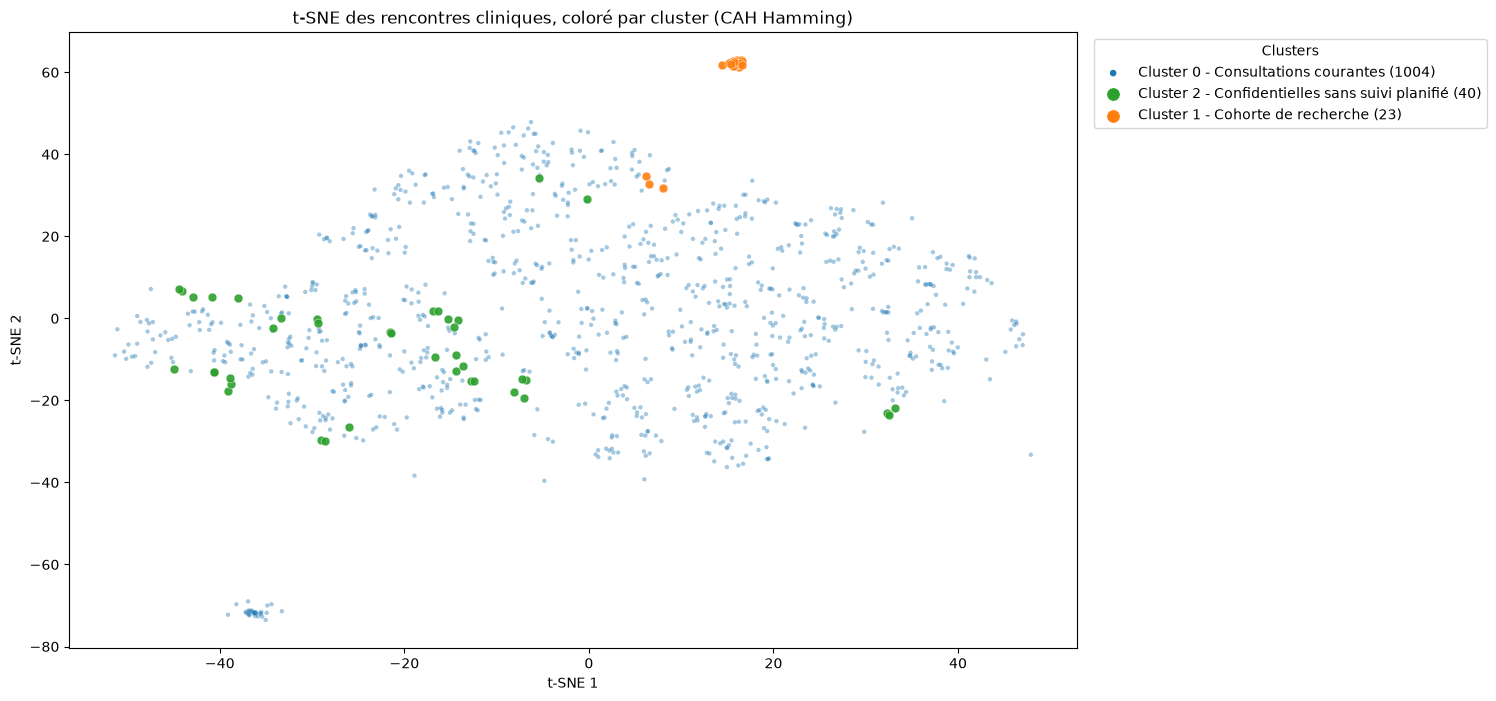

In [13]:
# Visualisation des clusters sur le t-SNE (une couleur par cluster)
noms = {0: 'Consultations courantes', 1: 'Cohorte de recherche', 2: 'Confidentielles sans suivi planifié'}
labels = encounters['Cluster_Agglom'].values
coords = encounters[['tSNE1', 'tSNE2']].values
# Beaucoup de points ont exactement le même profil (variables nominales) : on ajoute un léger bruit pour les voir
coords = coords + np.random.RandomState(0).normal(0, 0.02 * coords.std(0), coords.shape)

couleurs = sns.color_palette('tab10', k_optimal)
plt.figure(figsize=(13, 8))
# On dessine du plus gros au plus petit cluster pour que les petits groupes restent visibles
for c in np.argsort(-np.bincount(labels)):
    masque = labels == c
    gros = masque.sum() > 0.1 * len(labels)
    plt.scatter(coords[masque, 0], coords[masque, 1], color=couleurs[c],
                s=10 if gros else 40, alpha=0.4 if gros else 0.9, edgecolor='none' if gros else 'white', linewidth=0.3,
                label=f"Cluster {c} - {noms[c]} ({masque.sum()})")
plt.title('t-SNE des rencontres cliniques, coloré par cluster (CAH Hamming)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
leg = plt.legend(title='Clusters', loc='upper left', bbox_to_anchor=(1.01, 1), markerscale=1.5)
for h in getattr(leg, 'legend_handles', []):
    h.set_alpha(1)
plt.show()

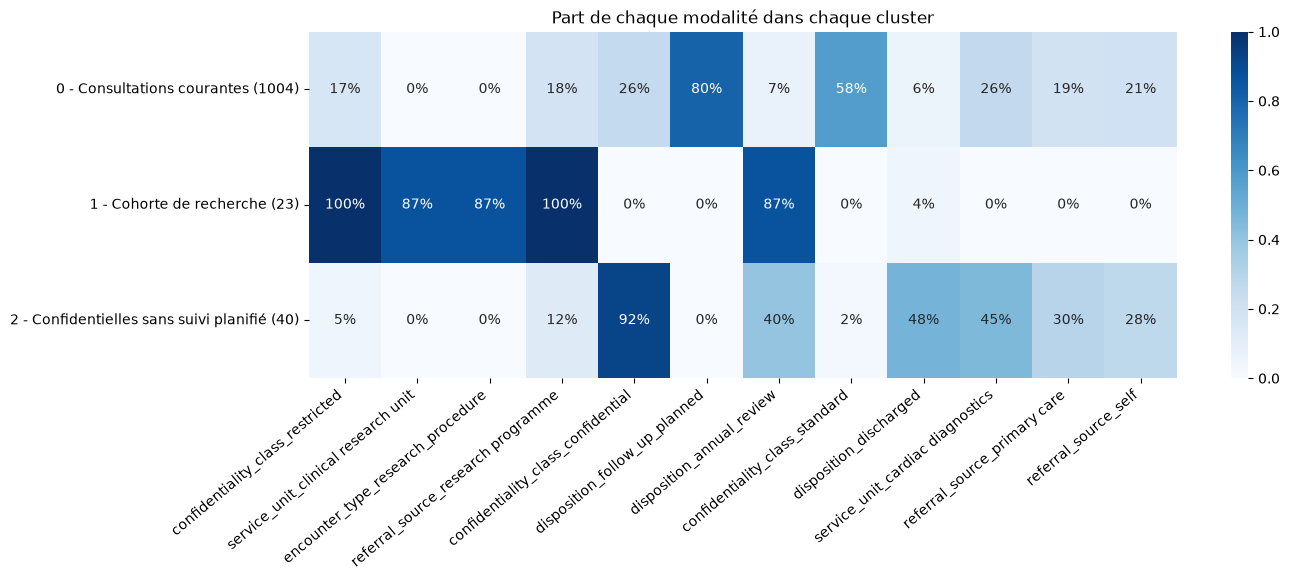

In [14]:
# Profil des clusters : part de chaque modalité dans chaque cluster (les 12 modalités qui différencient le plus les clusters)
profil = df_encoded.astype(float).groupby(labels).mean()
profil.index = [f"{c} - {noms[c]} ({(labels == c).sum()})" for c in profil.index]
top_modalites = profil.std().sort_values(ascending=False).head(12).index

plt.figure(figsize=(14, 4.5))
sns.heatmap(profil[top_modalites], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1)
plt.title('Part de chaque modalité dans chaque cluster')
plt.xticks(rotation=40, ha='right')
plt.show()

### c) Interpretations des clusters de clinical_encounters : 
- Cluster 0 - "Les Consultations Courantes" (1 004 cas) :   
Il regroupe l'essentiel des rencontres : suivis par des spécialistes (22.9%), examens généraux (21.7%), évaluations professionnelles (20.9%), etc. 80.4% débouchent sur un suivi planifié (follow_up_planned) et 57.8% sont de confidentialité standard. C'est le flux normal de l'hôpital. Le t-SNE montre pourtant un petit îlot isolé : les 30 procédures spécialisées (specialist_procedure, en specialist day unit, 100% restricted). La CAH les garde dans ce cluster (même pour k = 4 à 6), mais elles ressortent nettement dans clinical_procedures.  

- Cluster 1 - "La Cohorte de Recherche" (23 cas) :   
C'est un micro-groupe très restreint mais extrêmement homogène : 100% des rencontres viennent du research programme et sont de confidentialité restricted. 87.0% sont des procédures de recherche (research_procedure) effectuées dans la clinical research unit et liées à des revues annuelles (annual_review). Les 3 autres sont des suivis spécialisés du même programme.  

- Cluster 2 - "Les Consultations Confidentielles Sans Suivi Planifié" (40 cas) :   
92.5% sont confidential et aucune n'a de suivi planifié (follow_up_planned à 0%, alors que c'est le cas de 80.4% du cluster 0) : 47.5% sont clôturées (discharged) et 40.0% en revue annuelle. Le type de consultation est varié (specialist_follow_up 25.0%), ce sont donc la confidentialité et l'issue de la rencontre qui différencient ce groupe, pas l'activité médicale.  

Remarque : la silhouette est faible (0.16) et le K-Means ne retrouve pas ces groupes (ARI = 0.07). Seuls ces deux petits groupes ressortent du flux courant.

## 2. clinical_notes 

### a) choix des variables et encodage 

Nous allons donc faire le clustering uniquement sur les métadonnées de la note (par exemple : le type de note, le statut), et nous allons exclure la colonne de texte (pour l'instant).

In [15]:
cols_a_ignorer = ['document_id', 'patient_number', 'encounter_number', 'document_date', 
                  'author_license_number', 'facility_license_number', 'title', 'text']

cols_clustering = [c for c in notes.columns if c not in cols_a_ignorer]

print("Variables conservées pour le clustering :", cols_clustering)

Variables conservées pour le clustering : ['document_type', 'confidentiality_class']


In [16]:
# Tableau croisé pour voir les combinaisons existantes
tableau_croise = pd.crosstab(notes['document_type'], notes['confidentiality_class'])

print("Répartition des notes cliniques (Tableau Croisé) :")
print(tableau_croise)

Répartition des notes cliniques (Tableau Croisé) :
confidentiality_class    confidential  restricted  standard
document_type                                              
clinical_summary                    3           0         3
follow_up_note                      2           1         3
imaging_report                      2           1         3
occupational_assessment             3           2         1
specialist_consultation             1           3         2


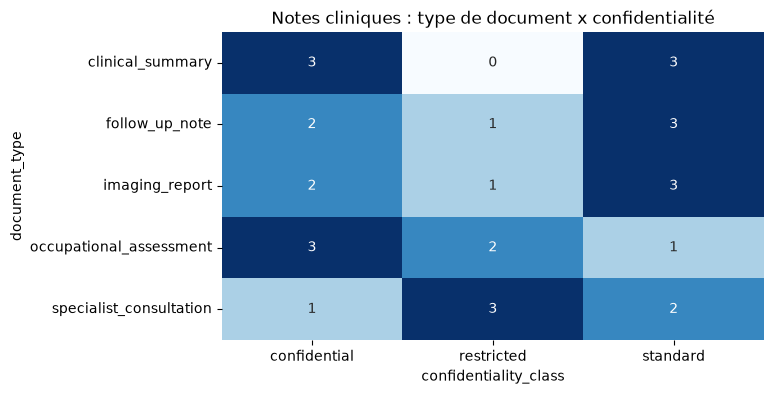

In [17]:
# Visualisation du tableau croisé
plt.figure(figsize=(7, 4))
sns.heatmap(tableau_croise, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Notes cliniques : type de document x confidentialité')
plt.show()

### Justification de l'absence de Clustering

Aucun algorithme de clustering n'a été appliqué sur le fichier `clinical_notes_clean.csv` 

**Pourquoi la méthode n'est pas pertinente ici ?**
1. **Insuffisance de variables :** Après exclusion des identifiants (patient, auteur, structure) et des dates, il ne reste que 2 variables purement nominales (`document_type` et `confidentiality_class`).
2. **Taille du dataset :** Le fichier ne contient que 30 observations. Un simple tableau croisé dynamique (crosstab) suffit à visualiser parfaitement la répartition des groupes.
3. **Nature de l'information :** La véritable valeur de ce dataset se trouve dans la colonne `text` que l'on traiera plus tard.

## 3. clinical_observation

### a) choix des variables et encodage 
Nous allons faire un clustering sur le contexte et la qualité des observations (les métadonnées qualitatives) en exluant donc les id, les dates et la numeric_value

In [18]:
cols_a_ignorer = ['observation_number', 'encounter_number', 'patient_number', 
                  'observation_time', 'assessor_license_number', 'observation_code', 
                  'text_value', 'numeric_value', 'unit', 'reference_range_text']

# Variables conservées : observation_name, interpretation_code, device_reference, quality_code
cols_clustering = [c for c in observation.columns if c not in cols_a_ignorer]

df_features = observation[cols_clustering].copy()

In [19]:
# Encodage One-Hot
df_encoded = pd.get_dummies(df_features, drop_first=False)

# Standardisation 
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

print(f"Dimensions avant One-Hot Encoding : {df_features.shape}")
print(f"Dimensions après One-Hot Encoding : {df_encoded.shape}")

Dimensions avant One-Hot Encoding : (17734, 4)
Dimensions après One-Hot Encoding : (17734, 47)


### b) PCA, t-SNE, et choix de la méthode de clustering

In [20]:
# --- PCA ---
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_encoded.values)
observation['PCA1'] = pca_result[:, 0]
observation['PCA2'] = pca_result[:, 1]

In [21]:
# --- t-SNE ---
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(df_encoded.values)
observation['tSNE1'] = tsne_result[:, 0]
observation['tSNE2'] = tsne_result[:, 1]

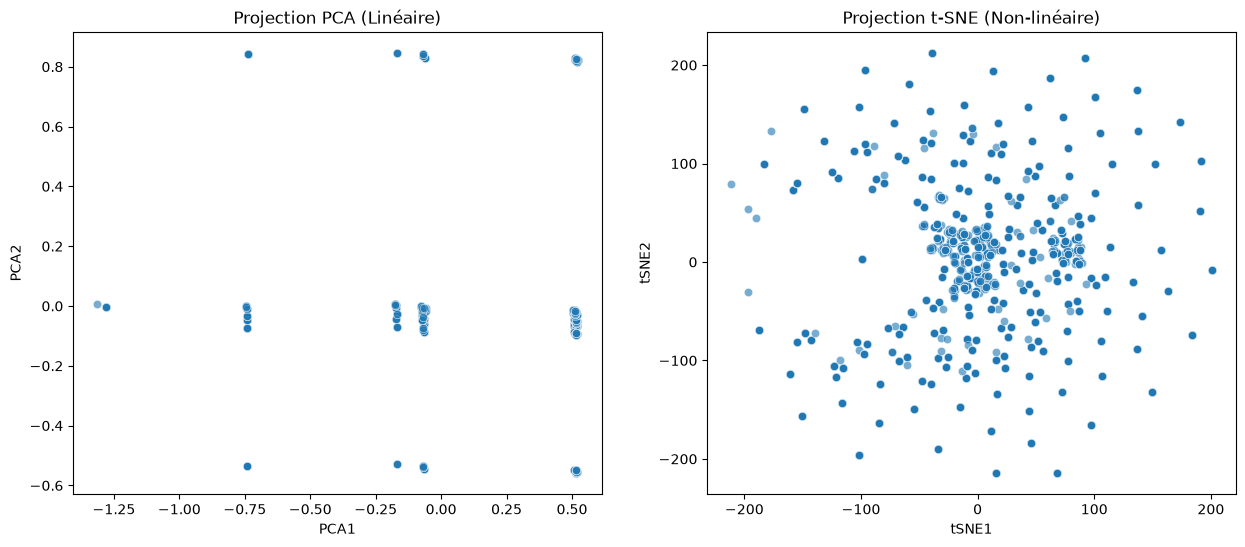

In [22]:
# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='PCA1', y='PCA2', data=observation, ax=axes[0], alpha=0.6)
axes[0].set_title('Projection PCA (Linéaire)')

sns.scatterplot(x='tSNE1', y='tSNE2', data=observation, ax=axes[1], alpha=0.6)
axes[1].set_title('Projection t-SNE (Non-linéaire)')
plt.show()

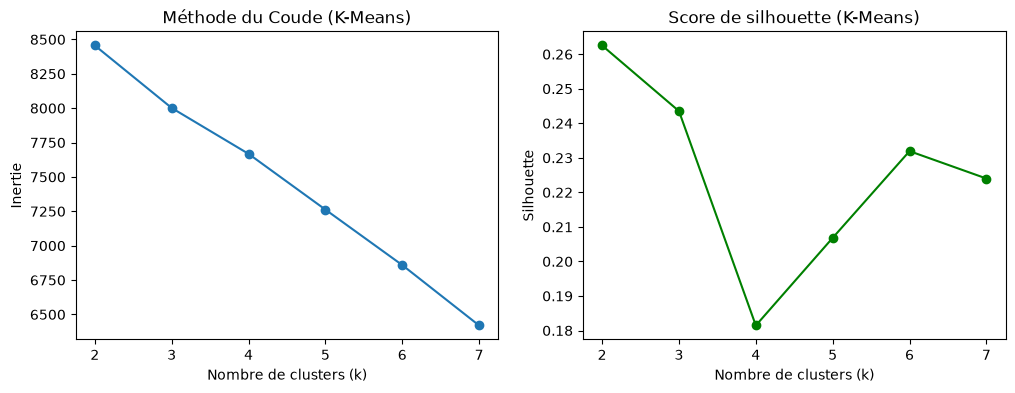

In [23]:
# --- Test K-MEANS (Coude + Silhouette) sur les variables one-hot brutes ---
# On utilise un échantillon aléatoire si le dataset est très grand pour gagner du temps
X_km = df_encoded.sample(n=min(5000, len(df_encoded)), random_state=42).values

inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_km = kmeans.fit_predict(X_km)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_km, labels_km))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Méthode du Coude (K-Means)')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[1].plot(K_range, silhouettes, marker='o', color='green')
axes[1].set_title('Score de silhouette (K-Means)')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Silhouette')
plt.show()

Le K-Means est testé sur les variables one-hot brutes (coude + silhouette), mais comme toutes les variables sont nominales on part sur le Clustering Agglomératif (avec Hamming), plus adapté d'après le cours, et on compare ensuite les deux. Les 17 734 observations ne correspondent en réalité qu'à 194 combinaisons de modalités différentes : les points du t-SNE se superposent donc en petits blocs.

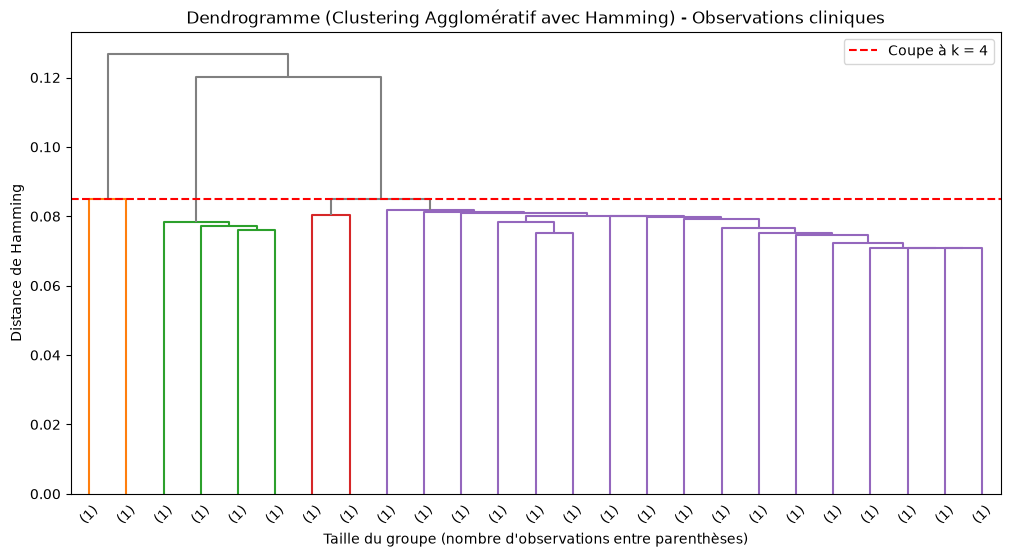

In [24]:
# Choix de K avec la méthode du dendogramme
# On utilise 'linkage' avec la métrique de Hamming sur toutes les lignes (comme l'AgglomerativeClustering plus bas),
# pour que le dendrogramme corresponde exactement aux clusters obtenus
Z = linkage(df_encoded.values.astype(float), method='average', metric='hamming')

# Hauteur de coupe qui donne k clusters (entre les deux dernières fusions conservées)
k_optimal = 4
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 6))
# (n) = nombre d'observations regroupées dans la branche ; (1) = observation seule
dendrogram(Z, truncate_mode='lastp', p=25, show_leaf_counts=True, leaf_label_func=lambda i: '(1)',
           color_threshold=seuil, above_threshold_color='grey')
plt.axhline(y=seuil, color='r', linestyle='--', label=f'Coupe à k = {k_optimal}')
plt.title("Dendrogramme (Clustering Agglomératif avec Hamming) - Observations cliniques")
plt.xlabel("Taille du groupe (nombre d'observations entre parenthèses)")
plt.ylabel("Distance de Hamming")
plt.legend()
plt.show()

In [25]:
# Silhouette de la CAH (Hamming) pour différents k, pour confirmer le choix de k
n_sil = min(5000, len(df_encoded))
for k in range(2, 7):
    labels_k = AgglomerativeClustering(n_clusters=k, metric='hamming', linkage='average').fit_predict(df_encoded)
    print(f"k = {k} : silhouette = {silhouette_score(df_encoded.values, labels_k, metric='hamming', sample_size=n_sil, random_state=42):.2f}")

k = 2 : silhouette = 0.43
k = 3 : silhouette = 0.42
k = 4 : silhouette = 0.26
k = 5 : silhouette = 0.24
k = 6 : silhouette = 0.26


On choisit k = 4, même si la silhouette (Hamming) est meilleure à k = 2 (0.43) et k = 3 (0.42) qu'à k = 4 (0.26). À k = 3, les mesures cardiaques apicales sont fusionnées avec les mesures dans la norme ; à k = 4 elles forment un groupe à part, ce qui a un sens médical. Le dendrogramme montre que ce choix est moins net statistiquement (les deux dernières fusions avant la coupe sont à une hauteur quasi identique, ~0.085).

In [26]:
k_optimal = 4

# L'Agglomératif sur de grosses bases de données peut saturer la RAM. 
try:
    agglom = AgglomerativeClustering(n_clusters=k_optimal, metric='hamming', linkage='average')
    observation['Cluster_Agglom'] = agglom.fit_predict(df_encoded)
    
    print("\nRépartition des observations par cluster :")
    print(observation['Cluster_Agglom'].value_counts())
    
    print("\n--- PROFIL TYPE DES CLUSTERS ---")
    for cluster in range(k_optimal):
        print(f"\n CLUSTER {cluster}")
        subset = observation[observation['Cluster_Agglom'] == cluster]
        for col in cols_clustering:
            if col in subset.columns:
                top_value = subset[col].mode()[0]
                pourcentage = (subset[col] == top_value).mean() * 100
                print(f"  > {col} : {top_value} ({pourcentage:.1f}%)")
except MemoryError:
    print("Le dataset est trop volumineux pour l'AgglomerativeClustering. Il faut utiliser une autre approche.")


Répartition des observations par cluster :
Cluster_Agglom
1    11250
0     5188
3     1017
2      279
Name: count, dtype: int64

--- PROFIL TYPE DES CLUSTERS ---

 CLUSTER 0
  > observation_name : ocular tracking interpretation (16.7%)
  > interpretation_code : recorded (100.0%)
  > device_reference : no_device (83.3%)
  > quality_code : acceptable (100.0%)

 CLUSTER 1
  > observation_name : peripheral oxygen saturation (9.0%)
  > interpretation_code : within_expected_range (99.6%)
  > device_reference : DEV-006 (11.7%)
  > quality_code : acceptable (100.0%)

 CLUSTER 2
  > observation_name : lateral sway index (39.4%)
  > interpretation_code : review (100.0%)
  > device_reference : DEV-007 (15.8%)
  > quality_code : acceptable (100.0%)

 CLUSTER 3
  > observation_name : apical cardiac rate (100.0%)
  > interpretation_code : within_expected_range (89.3%)
  > device_reference : DEV-006 (11.7%)
  > quality_code : acceptable (100.0%)


In [27]:
# Comparaison avec K-Means (sur les variables one-hot brutes, même nombre de clusters)
n_sil = min(5000, len(df_encoded))
labels = observation['Cluster_Agglom'].values
observation['Cluster_KMeans'] = KMeans(n_clusters=k_optimal, random_state=42, n_init=20).fit_predict(df_encoded.values)

print(f"Silhouette CAH (Hamming) : {silhouette_score(df_encoded.values, labels, metric='hamming', sample_size=n_sil, random_state=42):.2f}")
print(f"Silhouette K-Means       : {silhouette_score(df_encoded.values, observation['Cluster_KMeans'], sample_size=n_sil, random_state=42):.2f}")
print(f"ARI CAH vs K-Means       : {adjusted_rand_score(labels, observation['Cluster_KMeans']):.2f}")

print("\nCorrespondance CAH (lignes) / K-Means (colonnes) :")
print(pd.crosstab(observation['Cluster_Agglom'], observation['Cluster_KMeans']))

Silhouette CAH (Hamming) : 0.26
Silhouette K-Means       : 0.18
ARI CAH vs K-Means       : 0.51

Correspondance CAH (lignes) / K-Means (colonnes) :
Cluster_KMeans     0     1     2     3
Cluster_Agglom                        
0               5188     0     0     0
1                  0  2477  7592  1181
2                  0    51   192    36
3                  0   223   687   107


Le K-Means retrouve exactement le cluster 0 de la CAH (les 5 188 observations « recorded ») mais découpe le reste différemment (ARI = 0.51). Les silhouettes (0.26 pour la CAH, 0.18 pour le K-Means) confirment que la CAH avec Hamming est mieux adaptée à ces variables nominales.

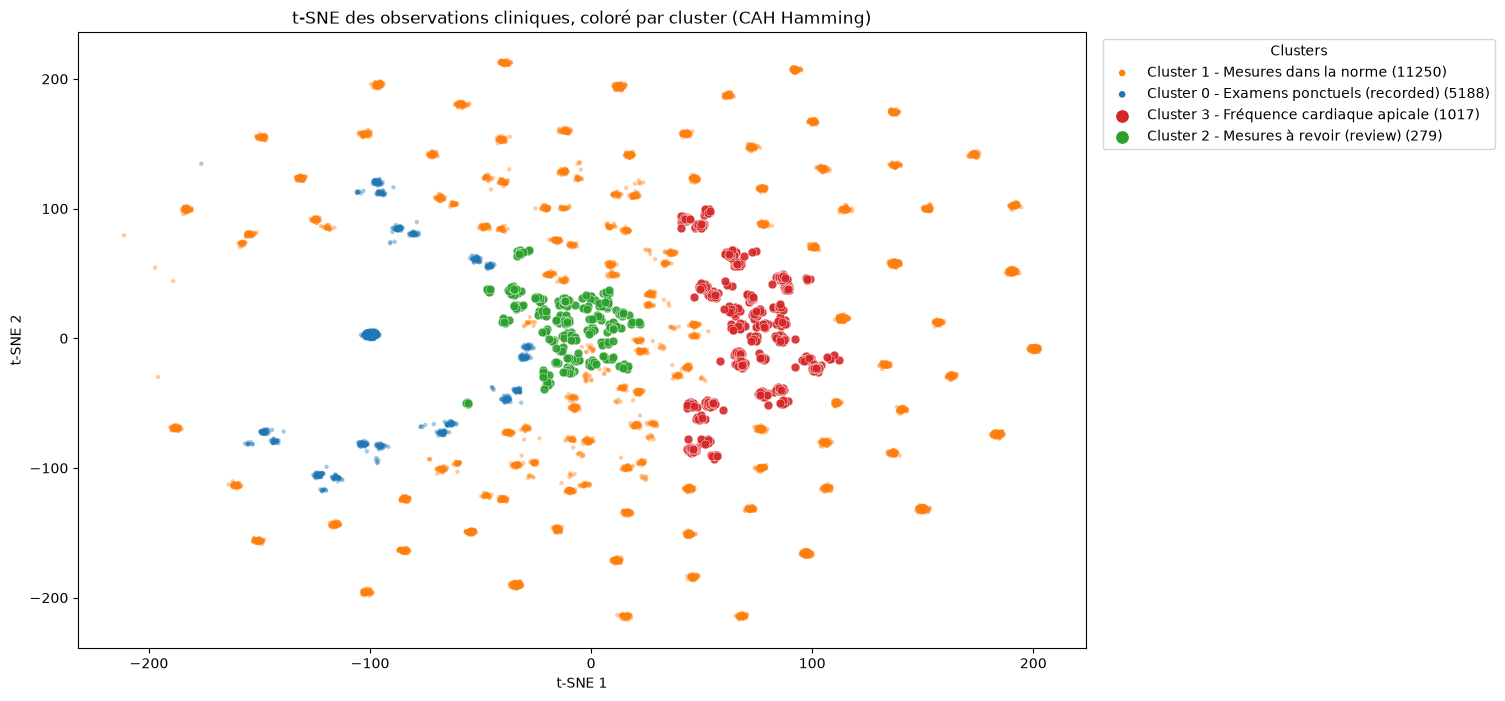

In [28]:
# Visualisation des clusters sur le t-SNE (une couleur par cluster)
noms = {0: 'Examens ponctuels (recorded)', 1: 'Mesures dans la norme', 2: 'Mesures à revoir (review)', 3: 'Fréquence cardiaque apicale'}
labels = observation['Cluster_Agglom'].values
coords = observation[['tSNE1', 'tSNE2']].values
# Beaucoup de points ont exactement le même profil (variables nominales) : on ajoute un léger bruit pour les voir
coords = coords + np.random.RandomState(0).normal(0, 0.01 * coords.std(0), coords.shape)

couleurs = sns.color_palette('tab10', k_optimal)
plt.figure(figsize=(13, 8))
# On dessine du plus gros au plus petit cluster pour que les petits groupes restent visibles
for c in np.argsort(-np.bincount(labels)):
    masque = labels == c
    gros = masque.sum() > 0.1 * len(labels)
    plt.scatter(coords[masque, 0], coords[masque, 1], color=couleurs[c],
                s=10 if gros else 40, alpha=0.4 if gros else 0.9, edgecolor='none' if gros else 'white', linewidth=0.3,
                label=f"Cluster {c} - {noms[c]} ({masque.sum()})")
plt.title('t-SNE des observations cliniques, coloré par cluster (CAH Hamming)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
leg = plt.legend(title='Clusters', loc='upper left', bbox_to_anchor=(1.01, 1), markerscale=1.5)
for h in getattr(leg, 'legend_handles', []):
    h.set_alpha(1)
plt.show()

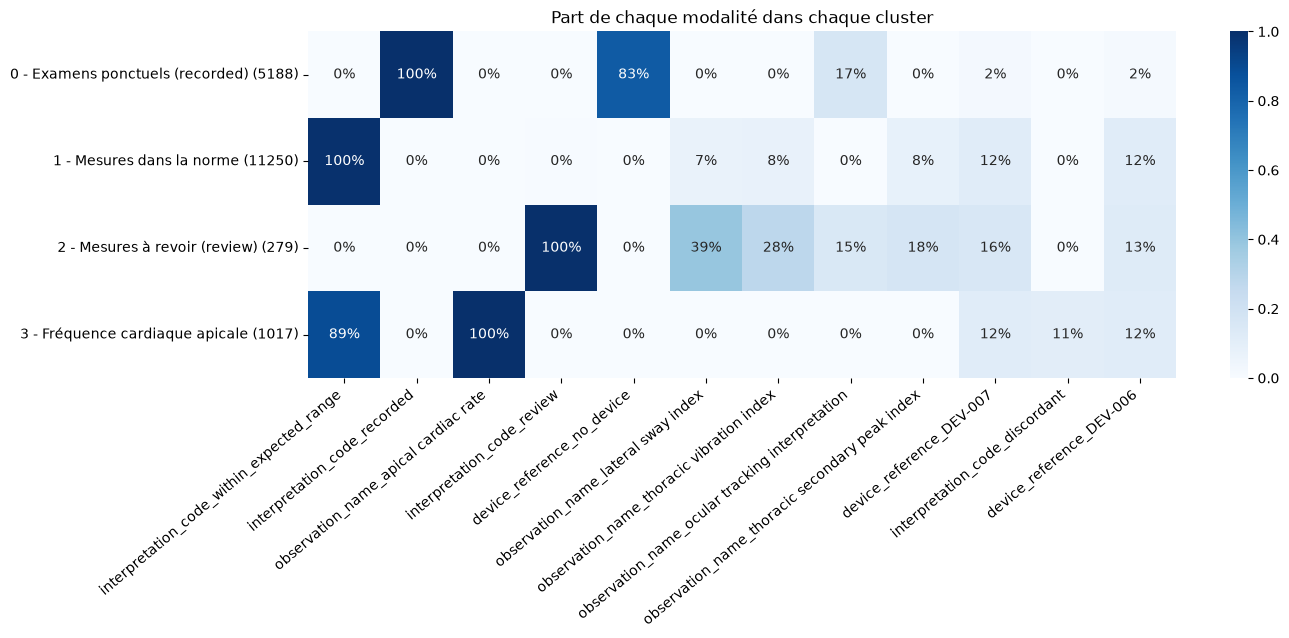

In [29]:
# Profil des clusters : part de chaque modalité dans chaque cluster (les 12 modalités qui différencient le plus les clusters)
profil = df_encoded.astype(float).groupby(labels).mean()
profil.index = [f"{c} - {noms[c]} ({(labels == c).sum()})" for c in profil.index]
top_modalites = profil.std().sort_values(ascending=False).head(12).index

plt.figure(figsize=(14, 4.5))
sns.heatmap(profil[top_modalites], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1)
plt.title('Part de chaque modalité dans chaque cluster')
plt.xticks(rotation=40, ha='right')
plt.show()

In [30]:
# --- DBSCAN ---
dbscan = DBSCAN(eps=1.5, min_samples=10)
observation['Cluster_DBSCAN'] = dbscan.fit_predict(df_scaled)

print("\nRépartition DBSCAN (-1 = anomalies / observations atypiques) :")
print(observation['Cluster_DBSCAN'].value_counts())


Répartition DBSCAN (-1 = anomalies / observations atypiques) :
Cluster_DBSCAN
149    240
150    240
151    240
152    240
153    240
      ... 
126     11
17      10
64      10
116     10
131     10
Name: count, Length: 168, dtype: int64


Le DBSCAN n'est pas exploitable ici : comme beaucoup d'observations ont exactement le même profil, chaque combinaison fréquente de modalités forme son propre cluster (167 clusters, plus 141 observations de bruit). On ne l'interprète donc pas, la détection d'anomalies sera faite au bloc 3.

### c) Interpretations des clusters de clinical_observation : 


- Cluster 1 - "Les Mesures dans la Norme" (11 250 observations) :
C'est le groupe majoritaire. Il regroupe 12 types de mesures numériques (pouls au repos, pouls périphérique, saturation en oxygène, score cognitif, équilibre, ...) qui pèsent à peu près autant les unes que les autres. 99.6% de ces mesures sont interprétées comme normales (within_expected_range), la qualité est toujours acceptable et presque toutes sont faites avec un appareil (DEV-001 à DEV-009). C'est le flux habituel de mesures.

- Cluster 0 - "Les Examens Ponctuels" (5 188 observations) :
Toutes les observations ont le statut « enregistré » (recorded à 100%), sans interprétation « dans la norme » ni « à revoir », et 83.3% sont faites sans appareil (no_device). Ce groupe est une batterie d'examens faite une seule fois par patient (240 observations chacun : tension artérielle, vitesse de marche, symétrie de la démarche, déviations oculaires, ...) à laquelle s'ajoute le suivi oculaire (ocular tracking interpretation, 868 observations). Ce sont plutôt des examens cliniques manuels ou qualitatifs réalisés par le médecin.

- Cluster 2 - "Les Mesures à Revoir" (279 observations) :
100% de ces observations nécessitent une révision (review) : c'est l'essentiel des 326 mesures marquées review (les 47 autres sont dans le cluster 1). Elles portent sur 4 types de mesures : l'indice de balancement latéral (lateral sway index, 39.4%), l'indice de vibration thoracique (28.0%), l'indice du pic thoracique secondaire (17.6%) et le suivi oculaire (15.1%). Toutes sont faites avec un appareil, avec une qualité acceptable. Attention, ce sont des mesures et pas des patients : on ne peut pas en déduire que ces patients ont des anomalies de démarche.

- Cluster 3 - "Les Mesures Cardiaques Apicales" (1 017 observations) :
100% de ces observations sont la fréquence cardiaque apicale (apical cardiac rate), une par rencontre. 89.3% sont dans la norme (within_expected_range) et les 10.7% restantes (109 observations) sont marquées discordant : ce sont les seules observations discordantes de toute la table et elles ne concernent que le pouls apical (35 patients). Piste pour le bloc 3 : cette discordance est à comparer avec le pouls périphérique.

Remarque : la silhouette de la CAH est faible (0.26) : les clusters décrivent surtout le type de mesure et son interprétation (normal, à revoir, enregistré), pas des profils de patients.

## 4. clinical_procedures

### a) choix des variables et encodage

On va exclure les id, les dates, les champs libres et aussi procedure_code qui va etre trop specifique et risque d'éclater les clusters 

In [31]:
cols_a_ignorer = ['procedure_record_id', 'encounter_number', 'patient_number', 
                  'procedure_code', 'procedure_description', 'scheduled_time', 
                  'performed_time', 'performing_facility_license', 
                  'performing_license_number', 'next_review_date']

cols_clustering = [c for c in procedure.columns if c not in cols_a_ignorer]
print("Variables conservées pour le clustering :", cols_clustering)

df_features = procedure[cols_clustering].copy()

Variables conservées pour le clustering : ['authorization_class', 'material_reference', 'procedure_status', 'outcome_code']


In [32]:
# Encodage One-Hot
df_encoded = pd.get_dummies(df_features, drop_first=False)

# Standardisation
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

print(f"Dimensions avant One-Hot Encoding : {df_features.shape}")
print(f"Dimensions après One-Hot Encoding : {df_encoded.shape}")

Dimensions avant One-Hot Encoding : (310, 4)
Dimensions après One-Hot Encoding : (310, 62)


### b) PCA, t-SNE, et choix de la méthode de clustering

In [33]:
# --- PCA ---
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_encoded.values)
procedure['PCA1'] = pca_result[:, 0]
procedure['PCA2'] = pca_result[:, 1]

In [34]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(df_encoded.values)
procedure['tSNE1'] = tsne_result[:, 0]
procedure['tSNE2'] = tsne_result[:, 1]

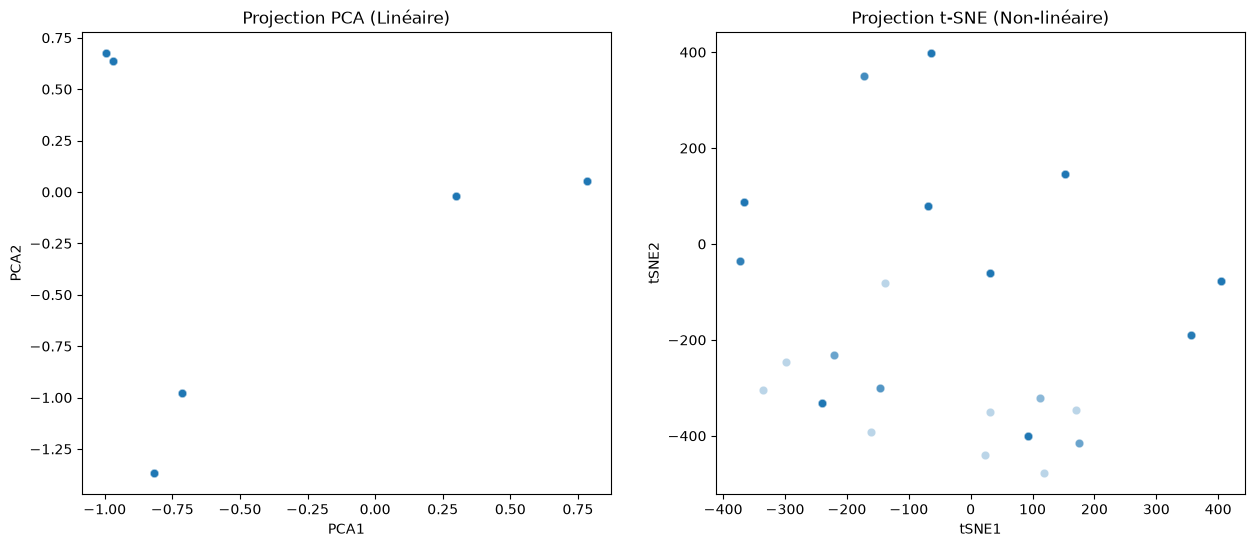

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='PCA1', y='PCA2', data=procedure, ax=axes[0], alpha=0.3)
axes[0].set_title('Projection PCA (Linéaire)')

sns.scatterplot(x='tSNE1', y='tSNE2', data=procedure, ax=axes[1], alpha=0.3)
axes[1].set_title('Projection t-SNE (Non-linéaire)')
plt.show()

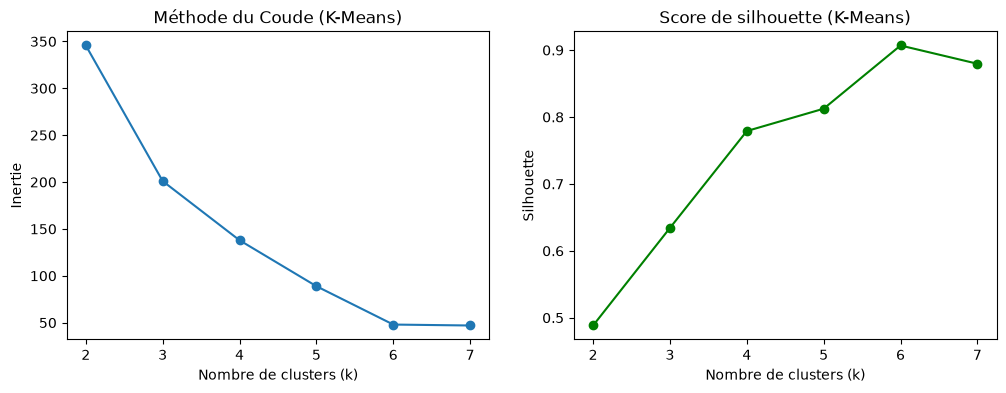

In [36]:
# --- Test K-MEANS (Coude + Silhouette) sur les variables one-hot brutes ---
inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_km = kmeans.fit_predict(df_encoded.values)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(df_encoded.values, labels_km))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Méthode du Coude (K-Means)')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[1].plot(K_range, silhouettes, marker='o', color='green')
axes[1].set_title('Score de silhouette (K-Means)')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Silhouette')
plt.show()

Les variables sont toutes nominales : on part sur le Clustering Agglomératif (avec Hamming), plus adapté d'après le cours, et on le compare ensuite à un K-Means. Les 310 procédures ne correspondent qu'à 54 combinaisons de modalités différentes, les points se superposent donc en petits blocs sur le t-SNE.

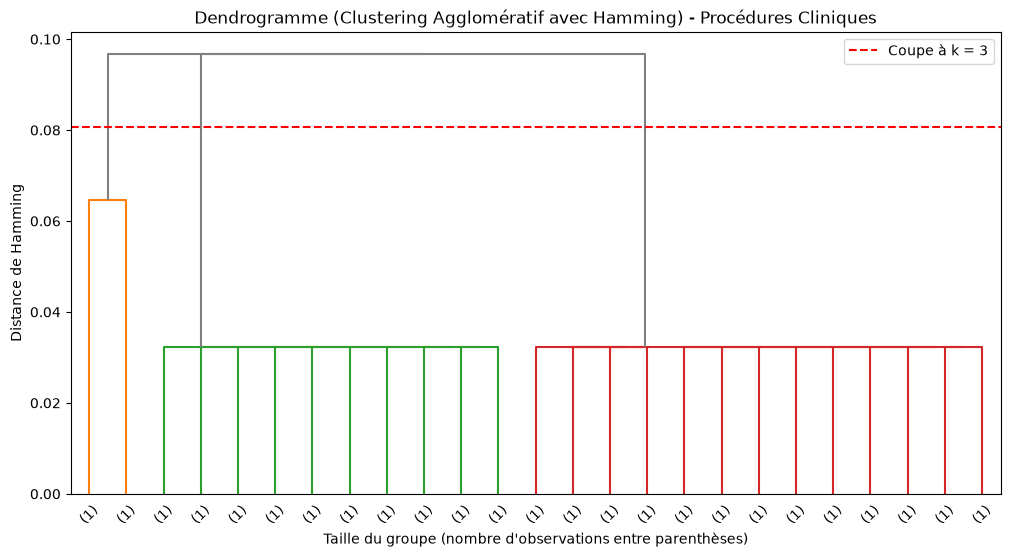

In [37]:
# Choix de K avec la méthode du dendogramme
# On utilise 'linkage' avec la métrique de Hamming sur toutes les lignes (comme l'AgglomerativeClustering plus bas),
# pour que le dendrogramme corresponde exactement aux clusters obtenus
Z = linkage(df_encoded.values.astype(float), method='average', metric='hamming')

# Hauteur de coupe qui donne k clusters (entre les deux dernières fusions conservées)
k_optimal = 3
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 6))
# (n) = nombre d'observations regroupées dans la branche ; (1) = observation seule
dendrogram(Z, truncate_mode='lastp', p=25, show_leaf_counts=True, leaf_label_func=lambda i: '(1)',
           color_threshold=seuil, above_threshold_color='grey')
plt.axhline(y=seuil, color='r', linestyle='--', label=f'Coupe à k = {k_optimal}')
plt.title("Dendrogramme (Clustering Agglomératif avec Hamming) - Procédures Cliniques")
plt.xlabel("Taille du groupe (nombre d'observations entre parenthèses)")
plt.ylabel("Distance de Hamming")
plt.legend()
plt.show()

In [38]:
# Silhouette de la CAH (Hamming) pour différents k, pour confirmer le choix de k
n_sil = min(5000, len(df_encoded))
for k in range(2, 7):
    labels_k = AgglomerativeClustering(n_clusters=k, metric='hamming', linkage='average').fit_predict(df_encoded)
    print(f"k = {k} : silhouette = {silhouette_score(df_encoded.values, labels_k, metric='hamming', sample_size=n_sil, random_state=42):.2f}")

k = 2 : silhouette = 0.59
k = 3 : silhouette = 0.64
k = 4 : silhouette = 0.78
k = 5 : silhouette = 0.73
k = 6 : silhouette = 0.73


On choisit k = 3 : la silhouette (Hamming) est bonne (0.64) et le dendrogramme montre 3 branches nettes (260 / 30 / 20). À k = 4 la silhouette monte à 0.78 mais cela sépare seulement le flux standard en deux (autorisation standard / confidential), ce qui n'apporte rien pour l'analyse.

In [39]:
k_optimal = 3 

# Clustering agglomeratif avec distance de Hamming
agglom = AgglomerativeClustering(n_clusters=k_optimal, metric='hamming', linkage='average')
procedure['Cluster_Agglom'] = agglom.fit_predict(df_encoded)

print("Répartition des procedures par cluster :")
print(procedure['Cluster_Agglom'].value_counts())

print("\n--- PROFIL TYPE DES CLUSTERS ---")
for cluster in range(k_optimal):
    print(f"\n CLUSTER {cluster}")
    subset = procedure[procedure['Cluster_Agglom'] == cluster]
    
    # On regarde les valeurs majoritaires pour donner un sens métier au groupe
    for col in cols_clustering:
        if col in subset.columns:
            top_value = subset[col].mode()[0]
            pourcentage = (subset[col] == top_value).mean() * 100
            print(f"  > {col} : {top_value} ({pourcentage:.1f}%)")

Répartition des procedures par cluster :
Cluster_Agglom
0    260
2     30
1     20
Name: count, dtype: int64

--- PROFIL TYPE DES CLUSTERS ---

 CLUSTER 0
  > authorization_class : standard (68.5%)
  > material_reference : no_material (100.0%)
  > procedure_status : completed (100.0%)
  > outcome_code : assessment_completed (52.7%)

 CLUSTER 1
  > authorization_class : research_restricted (100.0%)
  > material_reference : MTL-R-2019-0049 (5.0%)
  > procedure_status : completed (100.0%)
  > outcome_code : research_protocol_completed (100.0%)

 CLUSTER 2
  > authorization_class : restricted_specialist (100.0%)
  > material_reference : MTL-2014-0029 (3.3%)
  > procedure_status : completed (100.0%)
  > outcome_code : completed_without_immediate_complication (100.0%)


In [40]:
# Comparaison avec K-Means (sur les variables one-hot brutes, même nombre de clusters)
n_sil = min(5000, len(df_encoded))
labels = procedure['Cluster_Agglom'].values
procedure['Cluster_KMeans'] = KMeans(n_clusters=k_optimal, random_state=42, n_init=20).fit_predict(df_encoded.values)

print(f"Silhouette CAH (Hamming) : {silhouette_score(df_encoded.values, labels, metric='hamming', sample_size=n_sil, random_state=42):.2f}")
print(f"Silhouette K-Means       : {silhouette_score(df_encoded.values, procedure['Cluster_KMeans'], sample_size=n_sil, random_state=42):.2f}")
print(f"ARI CAH vs K-Means       : {adjusted_rand_score(labels, procedure['Cluster_KMeans']):.2f}")

print("\nCorrespondance CAH (lignes) / K-Means (colonnes) :")
print(pd.crosstab(procedure['Cluster_Agglom'], procedure['Cluster_KMeans']))

Silhouette CAH (Hamming) : 0.64
Silhouette K-Means       : 0.63
ARI CAH vs K-Means       : 0.40

Correspondance CAH (lignes) / K-Means (colonnes) :
Cluster_KMeans    0   1   2
Cluster_Agglom             
0               178  82   0
1                 0   0  20
2                 0   0  30


Le K-Means (k = 3) isole exactement les mêmes 50 procédures (clusters 1 et 2 de la CAH réunis) : les deux méthodes s'accordent sur la structure principale. L'ARI (0.40) n'est pas plus élevé parce que le K-Means coupe en plus le flux standard en deux (autorisation standard / confidential). Les silhouettes sont proches (0.64 pour la CAH, 0.63 pour le K-Means).

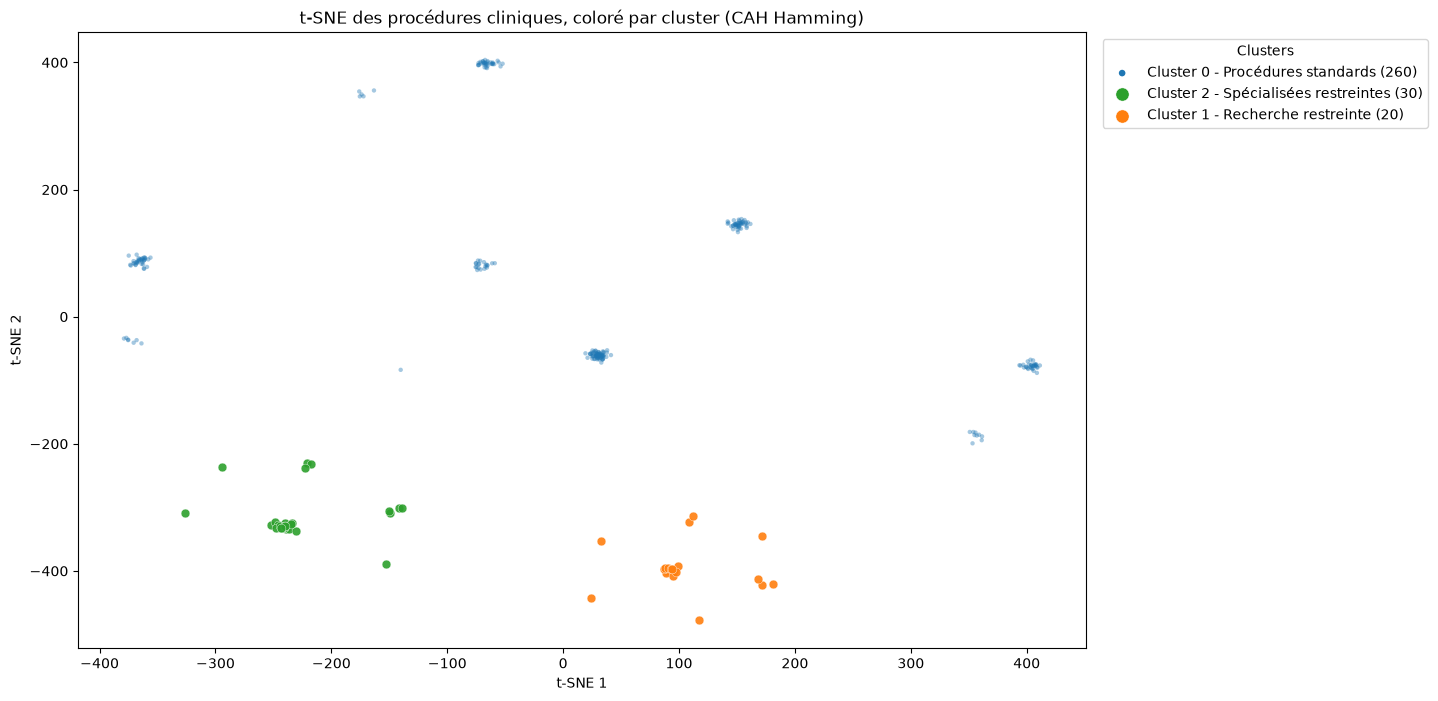

In [41]:
# Visualisation des clusters sur le t-SNE (une couleur par cluster)
noms = {0: 'Procédures standards', 1: 'Recherche restreinte', 2: 'Spécialisées restreintes'}
labels = procedure['Cluster_Agglom'].values
coords = procedure[['tSNE1', 'tSNE2']].values
# Beaucoup de points ont exactement le même profil (variables nominales) : on ajoute un léger bruit pour les voir
coords = coords + np.random.RandomState(0).normal(0, 0.02 * coords.std(0), coords.shape)

couleurs = sns.color_palette('tab10', k_optimal)
plt.figure(figsize=(13, 8))
# On dessine du plus gros au plus petit cluster pour que les petits groupes restent visibles
for c in np.argsort(-np.bincount(labels)):
    masque = labels == c
    gros = masque.sum() > 0.1 * len(labels)
    plt.scatter(coords[masque, 0], coords[masque, 1], color=couleurs[c],
                s=10 if gros else 40, alpha=0.4 if gros else 0.9, edgecolor='none' if gros else 'white', linewidth=0.3,
                label=f"Cluster {c} - {noms[c]} ({masque.sum()})")
plt.title('t-SNE des procédures cliniques, coloré par cluster (CAH Hamming)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
leg = plt.legend(title='Clusters', loc='upper left', bbox_to_anchor=(1.01, 1), markerscale=1.5)
for h in getattr(leg, 'legend_handles', []):
    h.set_alpha(1)
plt.show()

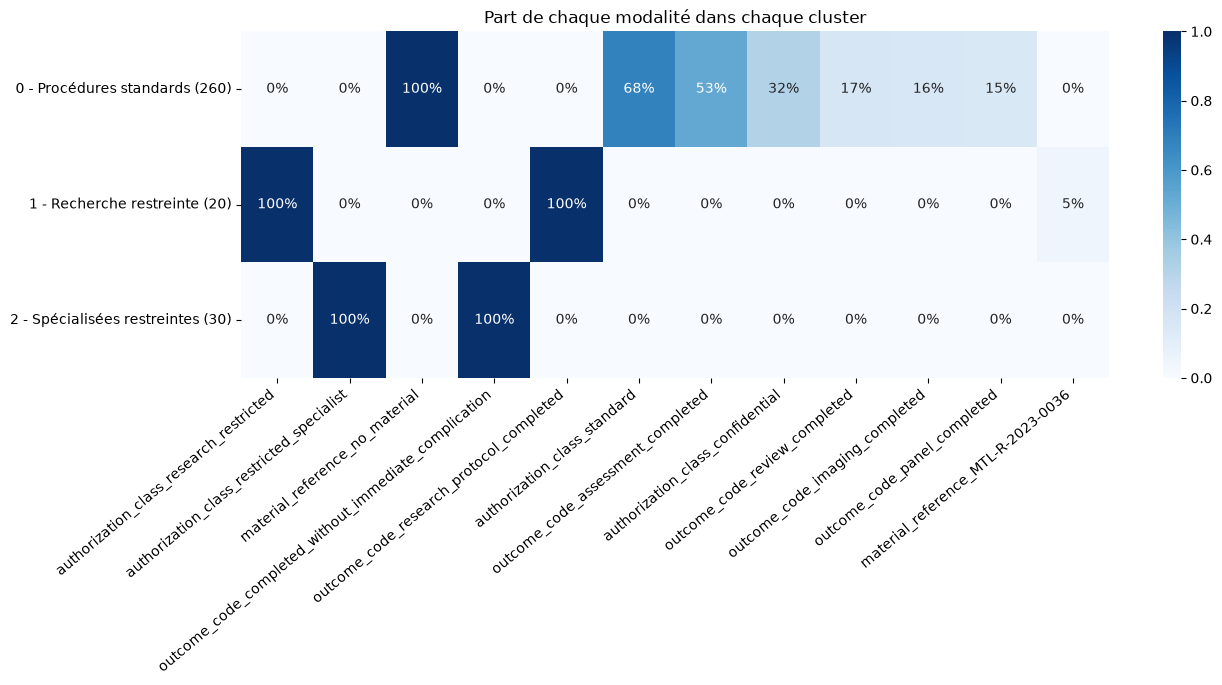

In [42]:
# Profil des clusters : part de chaque modalité dans chaque cluster (les 12 modalités qui différencient le plus les clusters)
profil = df_encoded.astype(float).groupby(labels).mean()
profil.index = [f"{c} - {noms[c]} ({(labels == c).sum()})" for c in profil.index]
top_modalites = profil.std().sort_values(ascending=False).head(12).index

plt.figure(figsize=(14, 4.5))
sns.heatmap(profil[top_modalites], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1)
plt.title('Part de chaque modalité dans chaque cluster')
plt.xticks(rotation=40, ha='right')
plt.show()

### c) Interpretations des clusters de clinical_procedure : 

- Cluster 0 - "Les Procédures Standards" (260 cas) :   
C'est le flux habituel : 68.5% sont sous autorisation standard et 31.5% confidential, aucune ne mobilise de matériel (no_material à 100%) et l'issue est une évaluation, une revue, une imagerie ou un panel terminé (assessment_completed 52.7%).  

- Cluster 1 - "La Recherche Clinique Restreinte" (20 cas) :   
Ce petit groupe de 20 procédures est 100% sous autorisation "research_restricted". L'issue de la procédure est toujours "protocole de recherche terminé" (research_protocol_completed à 100%). Chaque procédure utilise un matériel différent (20 références pour 20 procédures). Elles sont toutes liées à des rencontres de type research_procedure (cluster 1 de clinical_encounters).  

- Cluster 2 - "Les Procédures Spécialisées Restreintes" (30 cas) :   
100% de ces actes ont une classe d'autorisation "restricted_specialist". Le statut de sortie est systématiquement "terminé sans complication immédiate" (completed_without_immediate_complication à 100%). Là aussi chaque procédure a son propre matériel (30 références pour 30 procédures) et elles sont toutes liées à des rencontres specialist_procedure.  

Remarque : les clusters 1 et 2 correspondent exactement au code de procédure MRP-42 (Targeted metabolic resilience administration), alors que procedure_code n'a pas été utilisé pour le clustering. C'est le seul code qui mobilise du matériel et le seul réservé à un accès restreint. C'est la structure la plus nette du dossier health (silhouette de 0.64), confirmée par le K-Means.

## 5. patient_administration

### a) choix des variables et encodage

On garde encore une fois seulement les variables categorielles


In [43]:
cols_a_ignorer = ['patient_number', 'family_name', 'given_name', 
                  'date_of_birth', 'registration_date', 
                  'primary_facility_license', 'occupation_text']

cols_clustering = [c for c in patients.columns if c not in cols_a_ignorer]
print("Variables conservées pour le clustering :", cols_clustering)

df_features = patients[cols_clustering].copy()

Variables conservées pour le clustering : ['registered_sex', 'home_region', 'record_status']


In [44]:
# Encodage One-Hot
df_encoded = pd.get_dummies(df_features, drop_first=False)

# Standardisation
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_encoded)

print(f"Dimensions avant One-Hot Encoding : {df_features.shape}")
print(f"Dimensions après One-Hot Encoding : {df_encoded.shape}")

Dimensions avant One-Hot Encoding : (240, 3)
Dimensions après One-Hot Encoding : (240, 11)


### b) PCA, t-SNE, et choix de la méthode de clustering

In [45]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_encoded.values)
patients['PCA1'] = pca_result[:, 0]
patients['PCA2'] = pca_result[:, 1]

In [46]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(df_encoded.values)
patients['tSNE1'] = tsne_result[:, 0]
patients['tSNE2'] = tsne_result[:, 1]

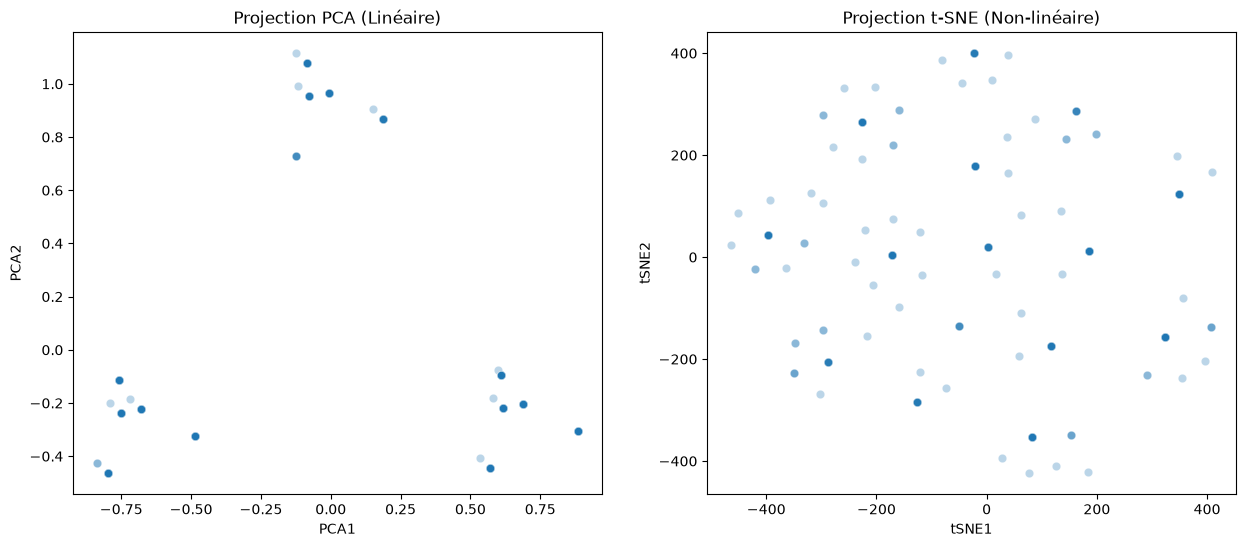

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x='PCA1', y='PCA2', data=patients, ax=axes[0], alpha=0.3)
axes[0].set_title('Projection PCA (Linéaire)')

sns.scatterplot(x='tSNE1', y='tSNE2', data=patients, ax=axes[1], alpha=0.3)
axes[1].set_title('Projection t-SNE (Non-linéaire)')
plt.show()

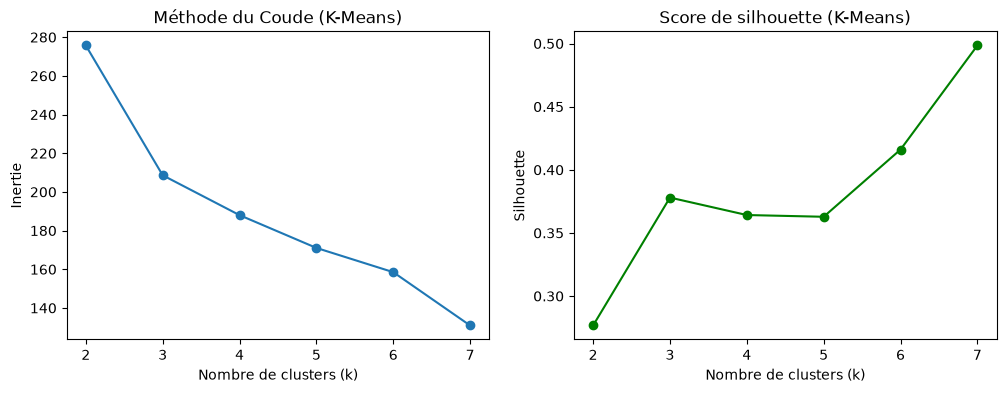

In [48]:
# --- Test K-MEANS (Coude + Silhouette) sur les variables one-hot brutes ---
inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_km = kmeans.fit_predict(df_encoded.values)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(df_encoded.values, labels_km))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Méthode du Coude (K-Means)')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[1].plot(K_range, silhouettes, marker='o', color='green')
axes[1].set_title('Score de silhouette (K-Means)')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Silhouette')
plt.show()

Les variables sont toutes nominales : on part sur le Clustering Agglomératif (avec Hamming), plus adapté d'après le cours, et on le compare ensuite à un K-Means. Les 240 patients ne correspondent qu'à 24 combinaisons de modalités (sexe, région, statut), les points se superposent donc en petits blocs sur le t-SNE.

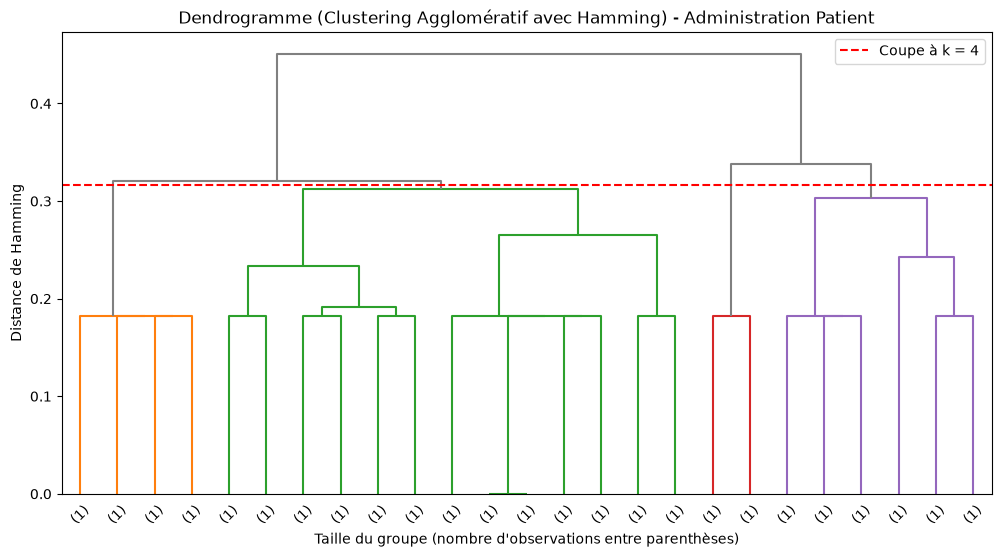

In [49]:
# Choix de K avec la méthode du dendogramme
# On utilise 'linkage' avec la métrique de Hamming sur toutes les lignes (comme l'AgglomerativeClustering plus bas),
# pour que le dendrogramme corresponde exactement aux clusters obtenus
Z = linkage(df_encoded.values.astype(float), method='average', metric='hamming')

# Hauteur de coupe qui donne k clusters (entre les deux dernières fusions conservées)
k_optimal = 4
seuil = (Z[-k_optimal, 2] + Z[-(k_optimal - 1), 2]) / 2

plt.figure(figsize=(12, 6))
# (n) = nombre d'observations regroupées dans la branche ; (1) = observation seule
dendrogram(Z, truncate_mode='lastp', p=25, show_leaf_counts=True, leaf_label_func=lambda i: '(1)',
           color_threshold=seuil, above_threshold_color='grey')
plt.axhline(y=seuil, color='r', linestyle='--', label=f'Coupe à k = {k_optimal}')
plt.title("Dendrogramme (Clustering Agglomératif avec Hamming) - Administration Patient")
plt.xlabel("Taille du groupe (nombre d'observations entre parenthèses)")
plt.ylabel("Distance de Hamming")
plt.legend()
plt.show()

In [50]:
# Silhouette de la CAH (Hamming) pour différents k, pour confirmer le choix de k
n_sil = min(5000, len(df_encoded))
for k in range(2, 7):
    labels_k = AgglomerativeClustering(n_clusters=k, metric='hamming', linkage='average').fit_predict(df_encoded)
    print(f"k = {k} : silhouette = {silhouette_score(df_encoded.values, labels_k, metric='hamming', sample_size=n_sil, random_state=42):.2f}")

k = 2 : silhouette = 0.41
k = 3 : silhouette = 0.32
k = 4 : silhouette = 0.27
k = 5 : silhouette = 0.39
k = 6 : silhouette = 0.38


On choisit k = 4, mais la silhouette (Hamming) n'indique aucun k clair (0.41 à k = 2, 0.27 à k = 4, 0.43 à k = 7) et le dendrogramme est en escalier : les clusters ne sont que des combinaisons de modalités (sexe, région, statut), pas des groupes naturels.

In [51]:
k_optimal = 4

# Application de l'algorithme Agglomératif avec la distance de Hamming
agglom = AgglomerativeClustering(n_clusters=k_optimal, metric='hamming', linkage='average')
patients['Cluster_Agglom'] = agglom.fit_predict(df_encoded)

print("Répartition des patients par cluster :")
print(patients['Cluster_Agglom'].value_counts())

print("\n--- PROFIL TYPE DES CLUSTERS ---")
for cluster in range(k_optimal):
    print(f"\n CLUSTER {cluster}")
    subset = patients[patients['Cluster_Agglom'] == cluster]
    
    for col in cols_clustering:
        if col in subset.columns:
            top_value = subset[col].mode()[0]
            pourcentage = (subset[col] == top_value).mean() * 100
            print(f"  > {col} : {top_value} ({pourcentage:.1f}%)")

Répartition des patients par cluster :
Cluster_Agglom
0    193
3     38
1      7
2      2
Name: count, dtype: int64

--- PROFIL TYPE DES CLUSTERS ---

 CLUSTER 0
  > registered_sex : female (48.7%)
  > home_region : nordhaven union (26.4%)
  > record_status : active (99.5%)

 CLUSTER 1
  > registered_sex : male (57.1%)
  > home_region : tembara commonwealth (42.9%)
  > record_status : inactive (100.0%)

 CLUSTER 2
  > registered_sex : nonbinary (100.0%)
  > home_region : avelora federation (50.0%)
  > record_status : inactive (100.0%)

 CLUSTER 3
  > registered_sex : nonbinary (100.0%)
  > home_region : avelora federation (31.6%)
  > record_status : active (100.0%)


In [52]:
# Comparaison avec K-Means (sur les variables one-hot brutes, même nombre de clusters)
n_sil = min(5000, len(df_encoded))
labels = patients['Cluster_Agglom'].values
patients['Cluster_KMeans'] = KMeans(n_clusters=k_optimal, random_state=42, n_init=20).fit_predict(df_encoded.values)

print(f"Silhouette CAH (Hamming) : {silhouette_score(df_encoded.values, labels, metric='hamming', sample_size=n_sil, random_state=42):.2f}")
print(f"Silhouette K-Means       : {silhouette_score(df_encoded.values, patients['Cluster_KMeans'], sample_size=n_sil, random_state=42):.2f}")
print(f"ARI CAH vs K-Means       : {adjusted_rand_score(labels, patients['Cluster_KMeans']):.2f}")

print("\nCorrespondance CAH (lignes) / K-Means (colonnes) :")
print(pd.crosstab(patients['Cluster_Agglom'], patients['Cluster_KMeans']))

Silhouette CAH (Hamming) : 0.27
Silhouette K-Means       : 0.36
ARI CAH vs K-Means       : 0.22

Correspondance CAH (lignes) / K-Means (colonnes) :
Cluster_KMeans   0   1   2   3
Cluster_Agglom                
0               10  94  67  22
1                1   2   4   0
2                2   0   0   0
3               38   0   0   0


Le K-Means (ARI = 0.22) regroupe les patients autrement : il sépare simplement par sexe, avec exactement les 51 patients nonbinary dans un cluster. Sa silhouette (0.36) est un peu meilleure que celle de la CAH (0.27), mais les deux restent faibles : avec ces 3 variables il n'y a pas de structure nette.

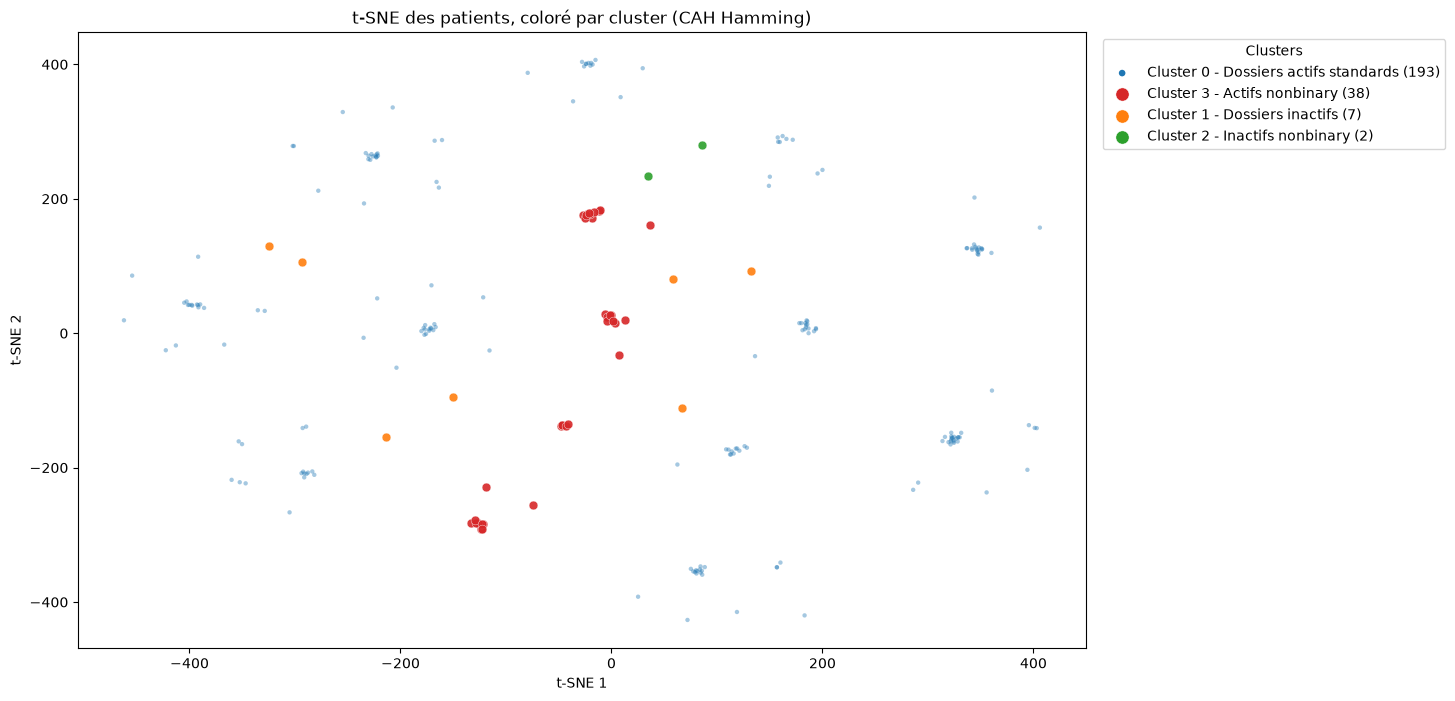

In [53]:
# Visualisation des clusters sur le t-SNE (une couleur par cluster)
noms = {0: 'Dossiers actifs standards', 1: 'Dossiers inactifs', 2: 'Inactifs nonbinary', 3: 'Actifs nonbinary'}
labels = patients['Cluster_Agglom'].values
coords = patients[['tSNE1', 'tSNE2']].values
# Beaucoup de points ont exactement le même profil (variables nominales) : on ajoute un léger bruit pour les voir
coords = coords + np.random.RandomState(0).normal(0, 0.02 * coords.std(0), coords.shape)

couleurs = sns.color_palette('tab10', k_optimal)
plt.figure(figsize=(13, 8))
# On dessine du plus gros au plus petit cluster pour que les petits groupes restent visibles
for c in np.argsort(-np.bincount(labels)):
    masque = labels == c
    gros = masque.sum() > 0.3 * len(labels)
    plt.scatter(coords[masque, 0], coords[masque, 1], color=couleurs[c],
                s=10 if gros else 40, alpha=0.4 if gros else 0.9, edgecolor='none' if gros else 'white', linewidth=0.3,
                label=f"Cluster {c} - {noms[c]} ({masque.sum()})")
plt.title('t-SNE des patients, coloré par cluster (CAH Hamming)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
leg = plt.legend(title='Clusters', loc='upper left', bbox_to_anchor=(1.01, 1), markerscale=1.5)
for h in getattr(leg, 'legend_handles', []):
    h.set_alpha(1)
plt.show()

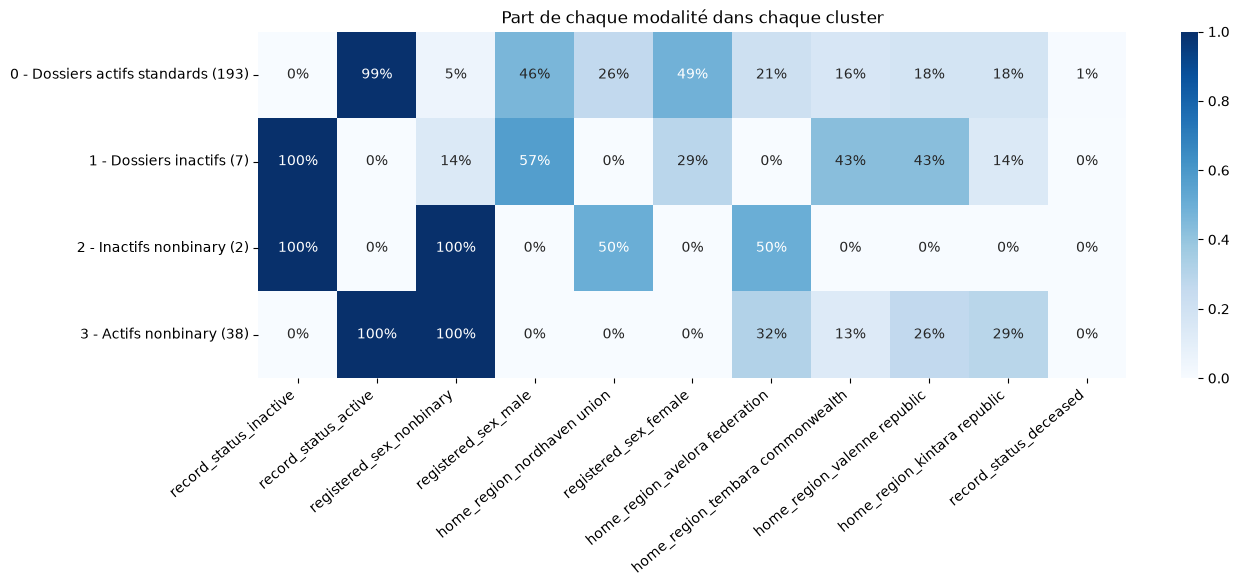

In [54]:
# Profil des clusters : part de chaque modalité dans chaque cluster (les 12 modalités qui différencient le plus les clusters)
profil = df_encoded.astype(float).groupby(labels).mean()
profil.index = [f"{c} - {noms[c]} ({(labels == c).sum()})" for c in profil.index]
top_modalites = profil.std().sort_values(ascending=False).head(12).index

plt.figure(figsize=(14, 4.5))
sns.heatmap(profil[top_modalites], annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1)
plt.title('Part de chaque modalité dans chaque cluster')
plt.xticks(rotation=40, ha='right')
plt.show()

### c) Interpretations des clusters de patient_administration :

- Cluster 0 — « Dossiers Actifs Standards » (193 patients) :   
C'est le socle principal de la base de données. Les dossiers sont quasiment tous actifs (active à 99,5 %, le seul dossier décédé de la base est ici), avec autant de femmes (94) que d'hommes (89), 10 patients nonbinary et les 5 régions représentées (Nordhaven Union 26,4 %).   

- Cluster 3 — « Actifs Nonbinary » (38 patients) :   
Un groupe défini par une identité nonbinary à 100 % et des dossiers tous actifs (active à 100 %). Ce sont 38 des 51 patients nonbinary de la base. La région est peu discriminante (Avelora Federation 31,6 %, Kintara Republic 28,9 %, Valenne Republic 26,3 %), sauf qu'aucun n'est de Nordhaven Union.   

- Cluster 1 — « Dossiers Inactifs » (7 patients) :   
Ce micro-groupe isole des dossiers archivés ou clos (inactive à 100 %), avec 4 hommes, 2 femmes et 1 patient nonbinary. Les régions sont dispersées (3 de Tembara Commonwealth, 3 de Valenne Republic, 1 de Kintara Republic), le statut est donc la seule variable qui définit ce groupe.   

- Cluster 2 — « Inactifs Nonbinary » (2 patients) :   
Deux dossiers inactifs de patients nonbinary (Avelora Federation et Nordhaven Union). Ce n'est pas une vraie anomalie, juste la combinaison rare nonbinary × inactive.   

Remarque : les 9 dossiers inactifs de la base sont répartis entre les clusters 1 et 2. Les clusters ne sont que des combinaisons de sexe et de statut (silhouette de 0.27, dendrogramme en escalier) : il n'y a pas de profils cachés avec ces 3 variables.